# Clustering DBSCAN en ML — Clustering Basado en Densidad

**CARLOS FRANCISCO MONTOYA URZUA**

**Fuente:** https://www.geeksforgeeks.org/machine-learning/dbscan-clustering-in-ml-density-based-clustering/

**fecha:** Miércoles, 20 de mayo  de 2026

---

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) es un algoritmo de clustering basado en densidad que agrupa los puntos de datos que están muy próximos entre sí y marca los valores atípicos como ruido en función de su densidad en el espacio de características. Identifica los clústeres como regiones densas en el espacio de datos, separadas por zonas de menor densidad.

A diferencia de K-Means o el clustering jerárquico, que asumen que los clústeres son compactos y esféricos, DBSCAN funciona bien para manejar irregularidades en datos del mundo real, como:

- **Clústeres de forma arbitraria:** Los clústeres pueden tener cualquier forma, no solo circular o convexa.
- **Ruido y valores atípicos:** Identifica y maneja eficazmente los puntos de ruido sin asignarlos a ningún clúster.

## Parámetros Clave en DBSCAN

### 1. `eps` (épsilon)
Define el radio de la vecindad alrededor de un punto de datos.

Si la distancia entre dos puntos es menor o igual a `eps`, se consideran vecinos.

Un método común para determinar `eps` es analizar el gráfico de distancia-k. Elegir el `eps` correcto es importante:

- Si `eps` es demasiado pequeño, la mayoría de los puntos se clasificarán como ruido.
- Si `eps` es demasiado grande, los clústeres pueden fusionarse y el algoritmo puede no distinguirlos.

### 2. `MinPts` (Puntos Mínimos)
Es el número mínimo de puntos requeridos dentro del radio `eps` para formar una región densa. La regla general es establecer `MinPts >= D + 1`, donde **D** es el número de dimensiones del conjunto de datos.

> Para la mayoría de los casos, se recomienda un valor mínimo de **`MinPts = 3`**.

## ¿Cómo Funciona DBSCAN?

DBSCAN funciona categorizando los puntos de datos en tres tipos:

1. **Puntos núcleo (*Core Points*):** tienen un número suficiente de vecinos dentro del radio especificado (`eps`).
2. **Puntos frontera (*Border Points*):** están cerca de los puntos núcleo pero no tienen suficientes vecinos para ser puntos núcleo por sí mismos.
3. **Puntos de ruido (*Noise Points*):** no pertenecen a ningún clúster.

Al expandir iterativamente los clústeres desde los puntos núcleo y conectar los puntos alcanzables por densidad, DBSCAN forma clústeres sin depender de suposiciones rígidas sobre su forma o tamaño.

### Pasos del Algoritmo DBSCAN

1. **Identificar Puntos Núcleo:** Para cada punto del conjunto de datos, se cuenta el número de puntos dentro de su vecindario `eps`. Si el recuento es igual o superior a `MinPts`, el punto se marca como punto núcleo.

2. **Formar Clústeres:** Para cada punto núcleo que aún no esté asignado a un clúster, se crea un nuevo clúster. Se encuentran recursivamente todos los puntos conectados por densidad —es decir, los puntos dentro del radio `eps` del punto núcleo— y se añaden al clúster.

3. **Conectividad por Densidad:** Dos puntos **a** y **b** están conectados por densidad si existe una cadena de puntos donde cada punto está dentro del radio `eps` del siguiente, y al menos un punto de la cadena es un punto núcleo. Este proceso de encadenamiento garantiza que todos los puntos de un clúster estén conectados a través de una serie de regiones densas.

4. **Etiquetar Puntos de Ruido:** Tras procesar todos los puntos, cualquier punto que no pertenezca a un clúster se etiqueta como ruido.

## Implementación del Algoritmo DBSCAN en Python

Aquí usaremos la biblioteca de Python `sklearn` para calcular el DBSCAN y la biblioteca `matplotlib.pyplot` para visualizar los clústeres.

---

### Paso 1: Importar las Librerías

Importamos todas las librerías necesarias: `numpy`, `matplotlib` y `scikit-learn`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn import metrics
from sklearn.metrics import adjusted_rand_score
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn import datasets

### Paso 2: Preparar el Conjunto de Datos

Crearemos un conjunto de datos de 4 clústeres usando `make_blobs`. El conjunto de datos tiene 300 puntos agrupados en 4 clústeres visibles.

In [27]:
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.50, random_state=0)

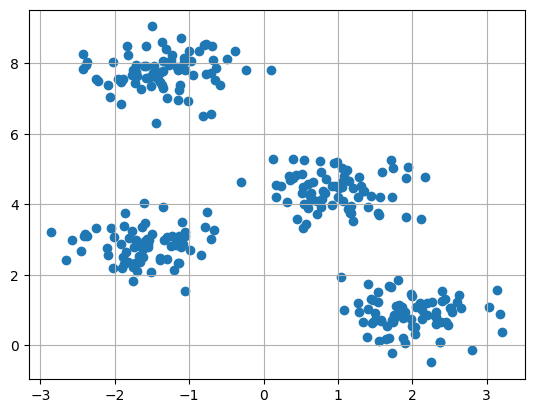

In [28]:
#BLOQUE AGREGADO PARA VER LOS CUMULOS
fig = plt.figure(0)
plt.grid(True)
plt.scatter(X[:, 0], X[:, 1])
plt.show()

### Paso 3: Aplicar el Clustering DBSCAN

Ahora aplicamos el clustering DBSCAN sobre nuestros datos, lo contamos y lo visualizamos usando la biblioteca `matplotlib`.

- **`eps=0.3`:** El radio para buscar puntos vecinos.
- **`min_samples`:** Número mínimo de puntos requeridos para formar una región densa (un clúster).
- **`labels`:** Números de clúster para cada punto. `-1` significa que el punto se considera ruido.

['y', 'b', 'g', 'r']


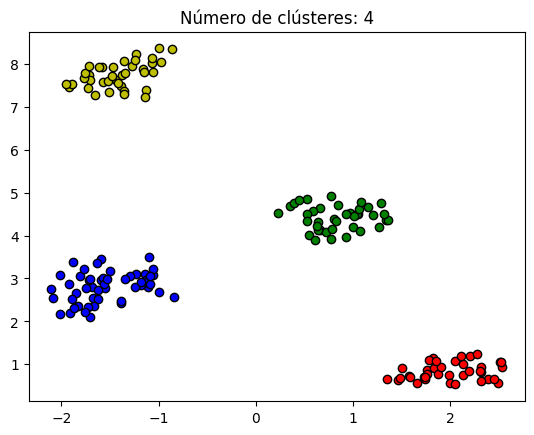

In [29]:
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

unique_labels = set(labels)
colors = ['y', 'b', 'g', 'r']
print(colors)
for k, col in zip(unique_labels, colors):
    if k == -1:
        # El negro se usa para el ruido.
        col = 'k'

    class_member_mask = (labels == k)

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col,
             markeredgecolor='k',
             markersize=6)

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col,
             markeredgecolor='k',
             markersize=6)

plt.title('Número de clústeres: %d' % n_clusters_)
plt.show()

**Salida:** Como se muestra en la imagen de salida, los clústeres se representan con diferentes colores: amarillo, azul, verde y rojo. Los puntos de ruido aparecen en negro.

---

### Paso 4: Métricas de Evaluación para el Algoritmo DBSCAN

Usaremos el **Coeficiente de Silueta** (*Silhouette Score*) y el **Índice de Rand Ajustado** (*Adjusted Rand Score*) para evaluar los algoritmos de clustering.

- **Coeficiente de Silueta:** Está en el rango de -1 a 1. Un puntaje cercano a **1** indica el mejor resultado, lo que significa que el punto de dato *i* está muy compacto dentro de su clúster y alejado de los otros. El peor valor es **-1**. Los valores cercanos a **0** indican clústeres superpuestos.

- **Índice de Rand Ajustado:** Está en el rango de 0 a 1. Un valor mayor a **0.9** indica una recuperación excelente de clústeres; por encima de **0.8** es una buena recuperación. Menos de **0.5** se considera una recuperación deficiente.

In [30]:
sc = metrics.silhouette_score(X, labels)
print("Coeficiente de Silueta: %0.2f" % sc)

ari = adjusted_rand_score(y_true, labels)
print("Índice de Rand Ajustado: %0.2f" % ari)

Coeficiente de Silueta: 0.13
Índice de Rand Ajustado: 0.31


**Salida esperada:**
```
Coeficiente de Silueta: 0.13
Índice de Rand Ajustado: 0.31
```

Los puntos negros representan valores atípicos (*outliers*). Modificando `eps` y `MinPts` podemos cambiar la configuración de los clústeres.

##INTENTO CON NUEVOS VALORES

In [35]:
#X, y_true = make_blobs(n_samples=300, centers=4,
#                       cluster_std=0.50, random_state=0)

X, y_true = make_blobs(n_samples=1000, centers=6,
                       cluster_std=1, random_state=40)

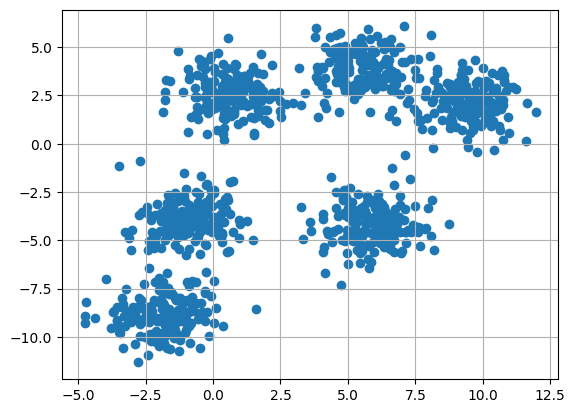

In [36]:
#BLOQUE AGREGADO PARA VER LOS CUMULOS
fig = plt.figure(0)
plt.grid(True)
plt.scatter(X[:, 0], X[:, 1])
plt.show()

['y', 'b', 'g', 'r']


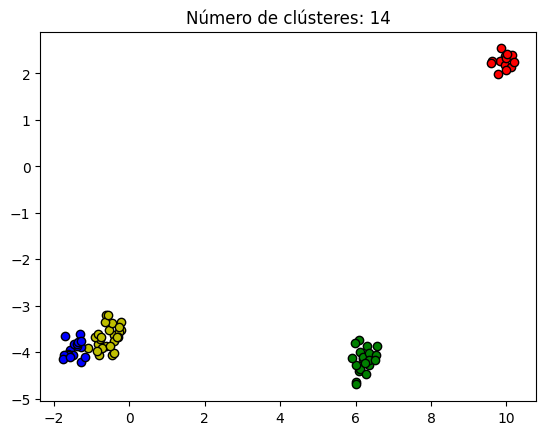

In [37]:
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_

n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)

unique_labels = set(labels)
colors = ['y', 'b', 'g', 'r']
print(colors)
for k, col in zip(unique_labels, colors):
    if k == -1:
        # El negro se usa para el ruido.
        col = 'k'

    class_member_mask = (labels == k)

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col,
             markeredgecolor='k',
             markersize=6)

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=col,
             markeredgecolor='k',
             markersize=6)

plt.title('Número de clústeres: %d' % n_clusters_)
plt.show()

In [38]:
sc = metrics.silhouette_score(X, labels)
print("Coeficiente de Silueta: %0.2f" % sc)

ari = adjusted_rand_score(y_true, labels)
print("Índice de Rand Ajustado: %0.2f" % ari)

Coeficiente de Silueta: -0.53
Índice de Rand Ajustado: 0.01


El coeficiente de la silueta indica que loss puntos estan muy poco compactos en su grupo

El indice de Rand muestra una recuperación mala de los puntos.

En este caso, el DBSCAN no funcionó correctamente.

## ¿Cuándo Usar DBSCAN en Lugar de K-Means?

DBSCAN y K-Means son ambos algoritmos de clustering que agrupan datos con características similares. Sin embargo, funcionan con principios diferentes y son adecuados para distintos tipos de datos. **Preferimos usar DBSCAN cuando los datos no tienen forma esférica o cuando el número de clases no se conoce de antemano.**

| **DBSCAN** | **K-Means** |
|---|---|
| No es necesario especificar el número de clústeres. | Es muy sensible al número de clústeres (*k*), que debe especificarse de antemano. |
| Los clústeres formados pueden tener cualquier forma arbitraria. | Los clústeres formados son esféricos o convexos. |
| Funciona bien con conjuntos de datos que tienen ruido y valores atípicos. | No funciona bien con datos atípicos. Los *outliers* pueden sesgar los clústeres en gran medida. |
| Se requieren dos parámetros para entrenar el modelo (`eps` y `MinPts`). | Solo se requiere un parámetro para entrenar el modelo (`k`). |

DBSCAN puede identificar clústeres de formas arbitrarias y manejar el ruido eficazmente. K-Means, por otro lado, es más adecuado para datos con clústeres bien definidos y esféricos, y es menos efectivo con ruido o estructuras de clústeres complejas.